# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

## Section 1 - Dataset
[Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)

In [21]:
from datasets import load_dataset, concatenate_datasets
from collections import Counter

ds = load_dataset("LabHC/bias_in_bios")
print(ds)  # train / dev / test, kolommen: hard_text, profession, gender

professions = [
    "accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
    "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
    "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
    "photographer", "physician", "poet", "professor", "psychologist", "rapper",
    "software_engineer", "surgeon", "teacher", "yoga_teacher",
]
genders = ["male", "female"]

train = ds["train"]
full_dataset = concatenate_datasets([
    ds["train"],
    ds["test"],
    ds["dev"]
])


# 1. Lege teksten?
for split in ds:
    print(split, "lege teksten:", sum(1 for t in ds[split]["hard_text"] if not t or not t.strip()))

# 2. Verdeling van beroepen (train)
prof_counts = Counter(full_dataset["profession"])
for idx, count in prof_counts.most_common():
    print(f"{professions[idx]:18s} {count:7d}  ({count/len(full_dataset):.1%})")

# 3. Verdeling van gender
gender_counts = Counter(full_dataset["gender"])
print({genders[k]: f"{v} ({v/len(full_dataset):.1%})" for k, v in gender_counts.items()})

# 4. Aandeel vrouwen per beroep (het belangrijkste voor de bias-analyse)
female_per_prof = Counter(p for p, g in zip(full_dataset["profession"], full_dataset["gender"]) if g == 1)
print("\nAandeel vrouwen per beroep:")
for idx in sorted(prof_counts, key=lambda i: female_per_prof[i] / prof_counts[i]):
    print(f"{professions[idx]:18s} {female_per_prof[idx]/prof_counts[idx]:.1%}")

# 5. Tekstlengte in woorden
lengths = [len(t.split()) for t in full_dataset["hard_text"]]
print(f"\nGemiddeld {sum(lengths)/len(lengths):.1f} woorden, min {min(lengths)}, max {max(lengths)}")

# 6. Verdeling per split vergelijken (zijn de splits vergelijkbaar?)
for split in ds:
    c = Counter(ds[split]["profession"])
    top3 = [(professions[i], f"{n/len(ds[split]):.1%}") for i, n in c.most_common(3)]
    print(split, top3)

# 7. Voorbeelden
for ex in full_dataset.shuffle(seed=42).select(range(5)):
    print(f"[{professions[ex['profession']]}, {genders[ex['gender']]}] {ex['hard_text'][:200]}")


DatasetDict({
    train: Dataset({
        features: ['hard_text', 'profession', 'gender'],
        num_rows: 257478
    })
    test: Dataset({
        features: ['hard_text', 'profession', 'gender'],
        num_rows: 99069
    })
    dev: Dataset({
        features: ['hard_text', 'profession', 'gender'],
        num_rows: 39642
    })
})
train lege teksten: 0
test lege teksten: 0
dev lege teksten: 0
professor           118076  (29.8%)
physician            40998  (10.3%)
attorney             32570  (8.2%)
photographer         24269  (6.1%)
journalist           19941  (5.0%)
nurse                18950  (4.8%)
psychologist         18380  (4.6%)
teacher              16203  (4.1%)
dentist              14585  (3.7%)
surgeon              13587  (3.4%)
architect            10108  (2.6%)
painter               7734  (2.0%)
model                 7491  (1.9%)
poet                  7014  (1.8%)
filmmaker             6996  (1.8%)
software_engineer     6912  (1.7%)
accountant            5633  (1.4%

In [53]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def plot_profession_distribution(
    dataset,
    professions,
    N_classes=10,
    show_gender=False,
    gender_names=None
):
    # Convert Hugging Face columns to Pandas Series
    profession_ids = pd.Series(dataset["profession"])
    gender = pd.Series(dataset["gender"])

    # Count professions by integer ID
    profession_counts = profession_ids.value_counts()

    # Select top N profession IDs
    top_ids = profession_counts.index[:N_classes]

    # Map integer IDs to profession names
    labels = [professions[int(i)] for i in top_ids]

    # Group remaining professions into Other
    rest_count = profession_counts.iloc[N_classes:].sum()

    if rest_count > 0:
        labels.append("Other")

    # Create a common plotting category for every sample
    id_to_name = {
        profession_id: professions[int(profession_id)]
        for profession_id in top_ids
    }

    plot_labels = profession_ids.map(id_to_name).fillna("Other")

    # Integer x-coordinates
    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(13, 6))

    if show_gender:
        # Optional mapping for integer gender labels
        if gender_names is not None:
            gender = gender.map(
                lambda g: gender_names.get(g, str(g))
            )

        # Count gender for each plotted profession
        gender_counts = pd.crosstab(plot_labels, gender)

        # Ensure all profession labels are present
        gender_counts = gender_counts.reindex(
            labels, fill_value=0
        )

        # Plot stacked bars
        bottom = np.zeros(len(labels))

        for gender_label in gender_counts.columns:
            values = gender_counts[gender_label].values

            ax.bar(
                x,
                values,
                bottom=bottom,
                label=str(gender_label)
            )

            bottom += values

        # Add total count above each bar
        for i, total in enumerate(bottom):
            ax.text(
                x[i],
                total,
                f"{total:,.0f}",
                ha="center",
                va="bottom",
                # rotation=10,
            )

        ax.legend(title="Gender")

    else:
        # Count samples per plotted category
        values = plot_labels.value_counts().reindex(
            labels, fill_value=0
        ).values

        bars = ax.bar(x, values)

        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f"{height:,.0f}",
                ha="center",
                va="bottom",
                # rotation=10,
            )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")

    ax.set_title(
        f"Profession Distribution (Top {N_classes} + Other)"
    )
    ax.set_xlabel("Profession")
    ax.set_ylabel("Number of samples")

    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


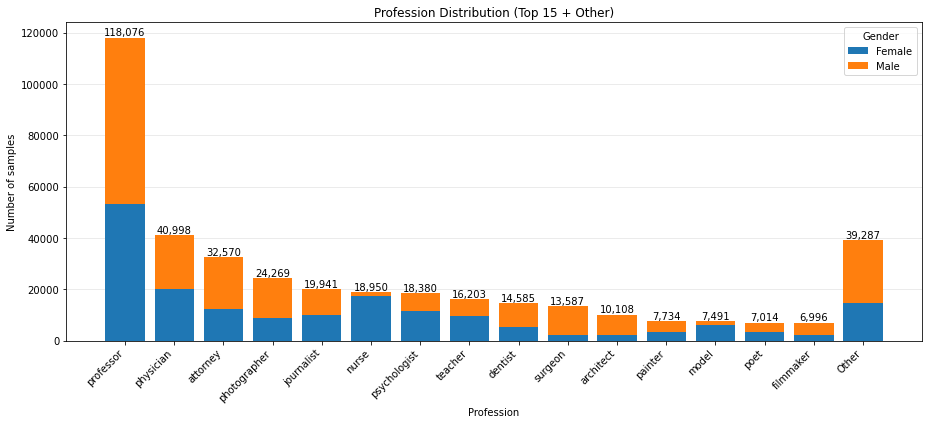

In [54]:
plot_profession_distribution(
    full_dataset,
    professions,
    N_classes=15,
    show_gender=True,
    gender_names={0: "Male", 1: "Female"}
)

## Section 2 - Tokenizers
Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.

## Section 3 - Encoders
Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 

In [59]:
import encoders
import utils

vocab_size = 1000
min_frequency = 2

corpus = utils.clean_corpus(ds["train"]["hard_text"])

print(f"Training on {len(corpus)} samples...")
tokenizer = encoders.train_tokenizer(corpus, vocab_size, min_frequency)
print("Tokennizer Trained\n")

print("Vocab:")
print(tokenizer.get_vocab())

token_indicator_encoder = encoders.TokenIndicator(tokenizer)


Training on 257478 samples...



Tokennizer Trained

Vocab:
{'▁Af': 741, 'all': 370, '▁su': 489, 'ric': 468, '6': 22, 'iverse': 985, '▁se': 446, 'ord': 556, '▁ex': 243, 'and': 285, 'ance': 384, '▁for': 163, '▁under': 837, '▁their': 626, 'ail': 850, '▁"': 932, 'ght': 746, 'rom': 198, 'ak': 315, 'ith': 169, 'ele': 990, 'ors': 516, '▁learn': 972, 'low': 930, '▁Med': 273, 'ig': 218, '▁par': 612, 'ant': 417, '▁well': 540, '▁f': 122, 'ross': 566, '▁at': 167, 'rop': 766, 'ays': 935, 'ow': 232, '▁Al': 591, 'ist': 267, '▁Y': 433, 'qu': 407, '▁4': 929, '▁graduated': 607, 'lec': 776, 'usic': 784, 'ual': 481, '▁s': 116, '▁col': 564, 'nder': 598, '=': 29, 'aw': 356, 'rim': 675, '▁eng': 988, 'P': 48, '▁information': 828, '▁College': 488, '▁M': 135, 'ud': 183, 'ust': 431, '▁receiv': 406, 'ore': 304, '▁Ins': 653, 'tive': 513, '▁it': 681, '2': 18, '▁incl': 276, '▁inter': 278, '▁Comp': 822, '▁hold': 765, '▁Engl': 666, 'en': 105, '#': 3, '▁v': 292, 'ilm': 669, 'se': 452, 'per': 271, 'ont': 674, '▁especia

In [58]:
# Examples
doc_repr = token_indicator_encoder(corpus[0])
print(len(doc_repr))
print(doc_repr.sum())

1000
81.0


## Section 4 - Text Classification
We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).

## Section 5 - Evaluation
Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?

## Section 6 - Conclusion
Analyse the various models you assessed and try to decide on which is the best.